# 4.1.1-Literature markers in tumor fraction

**Inés Sentís**

Check gene markers per subtype published in literature

Date of execution

In [1]:
Sys.Date()

[1] "2026-01-08"

## Libraries

In [2]:
suppressMessages(suppressWarnings({
library(Seurat)
library(Signac)
library(tidyverse)
library(scater) 
library(scran)
library(edgeR)
library(ggsignif)
library(ComplexHeatmap)
library(here)
library(glue)
}))

## Parameters

In [3]:
#here::dr_here(show_reason = TRUE)
source(here("utils/bin.R"))
source(here("utils/paths.R"))
source(here("AVGUSTINOVA_02_to_30/utils/style.R"))

set.seed(0)

In [4]:
lite_markers <- c("TYR","OTX2", "BMP4","FABP7","BOC","GLI2",
                "HOXB3", "HOXC9","MEOX2", "MEIS1", "SMOC2","SEMA3C","MYC")

In [5]:
scaling=FALSE

## Load Data

### Multiome

In [6]:
combined_obj <- readRDS(here(glue("{int}/{robj_dir}/4.1.0-tumor_fraction.rds")))

In [7]:
markers <- lite_markers

In [8]:
combined_obj <- SetIdent(combined_obj, value=combined_obj@meta.data$patient)

In [9]:
# create pseudobulks per ident and normalise as logCPM
list_objects <- SplitObject(combined_obj, split.by = "ident")
list_objects <- list_objects[match(levels(combined_obj), names(list_objects))]
col_names <-  names(list_objects)

counts <- matrix(nrow=dim(list_objects[[1]]@assays$RNA@counts)[1], ncol=0)
lib_sizes <- c()

for (d in col_names){
  obj <- list_objects[[d]]

  m <- as.matrix(obj@assays$RNA@counts)
  c <- rowSums(m)
  counts <- cbind(counts, c)

  ls <- sum(colSums(m))
  lib_sizes <- c(lib_sizes, ls)
}
colnames(counts)<-col_names

logCPM <- counts
for (i in seq_along(names(list_objects))){
  ls <- lib_sizes[i]
  d <- colnames(logCPM)[i]
  logCPM[, d]<-log2((logCPM[, d]/ls*1e6)+1) 
} 

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.8 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.2 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.7 GiB”


In [10]:
markers <- markers[markers %in% rownames(logCPM)]

In [11]:
# compute pecentatge of cells expressing each gene
percent_expression <- matrix(nrow = nrow(list_objects[[1]]@assays$RNA@counts), ncol = 0)

for (d in col_names) {
  obj <- list_objects[[d]]

  m <- as.matrix(obj@assays$RNA@counts)
  percent_expr <- rowMeans(m > 0) * 100  # Calculate the percentage of cells with non-zero expression
  percent_expression <- cbind(percent_expression, percent_expr)
}

colnames(percent_expression) <- col_names
rownames(percent_expression) <- rownames(list_objects[[1]]@assays$RNA@counts)

# transform the data

if (scaling == T) {
    # scaling as z-scoring 
    mat1 <- t(scale(t(logCPM)))
    mat1 <- mat1[unlist(markers, use.names = F),]

    # aesthetics for the dotplot
    pal_gradient = rev(c('#a50026','#d73027','#f46d43','#fdae61','#fee090','#ffffbf',
                                        '#e0f3f8','#abd9e9','#74add1','#4575b4','#313695'))
    leg_name =  "z-score\nnorm. expr."
} else {
    mat1 <- logCPM[unlist(markers, use.names = F),]
    viridis_reversed <- rev(viridisLite::viridis(n = 50, option = "D"))
    color_palette <- c("white", viridis_reversed)
    leg_name = "Expr.log(CPM)"
}

# from matrix to df for ggplot2
expression_df <- as.data.frame(mat1) %>%
rownames_to_column(var = "Gene")

expression_df <- expression_df %>%
    pivot_longer(
        cols = -Gene, 
        names_to = "Patient",  
        values_to = "Expression")

percent_expression_df <- as.data.frame(percent_expression) %>%
  rownames_to_column(var = "Gene") %>%
  pivot_longer(
    cols = -Gene,
    names_to = "Patient",
    values_to = "PercentExpressing"
  )
expression_df <- left_join(expression_df, percent_expression_df, by = c("Gene", "Patient"))

# set order
expression_df[["Patient"]] <- factor(expression_df[["Patient"]],
                                              levels=rev(col_names))

expression_df[["Gene"]] <- factor(expression_df[["Gene"]],
                                          levels=unlist(markers, use.names = F))

Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.8 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.6 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.2 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.3 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 1.1 GiB”
Warning message in asMethod(object):
“sparse->dense coercion: allocating vector of size 2.7 GiB”


In [12]:
custom_order <- c('p2','p8','p14','p17','p13','p9','p7','p6','p15','p10','p16','p3','p5','p1','p4','p19')
expression_df$Patient <- factor(expression_df$Patient, levels = custom_order)

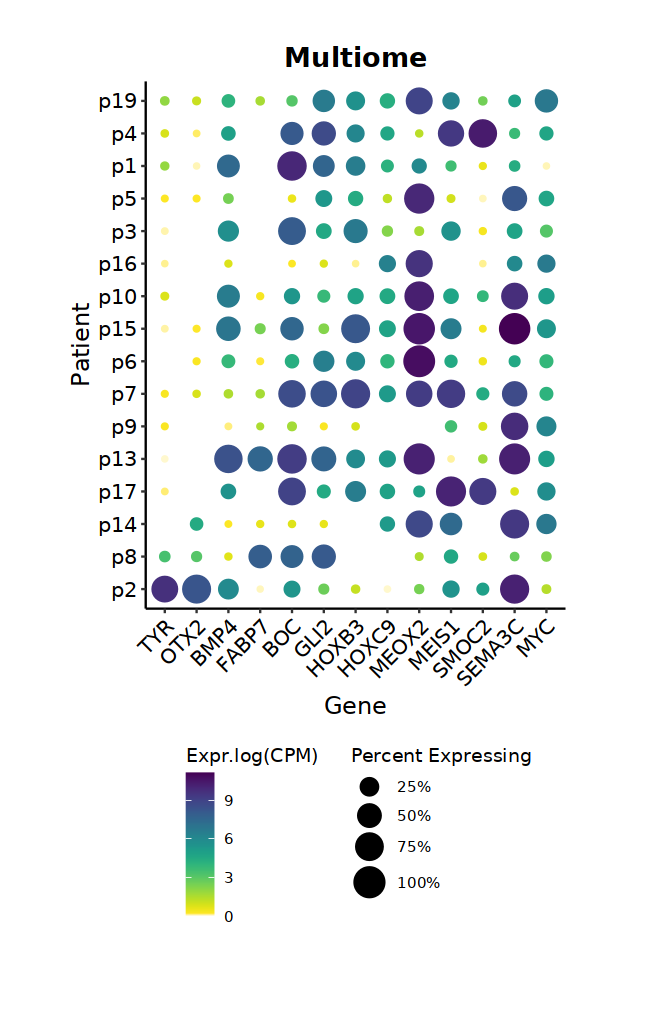

In [13]:
options(repr.plot.width = 5.5, repr.plot.height = 8.5, warn=-1,verbose = FALSE)

dp1 <-  ggplot(expression_df, aes(x = Patient, y = Gene)) +
  geom_point(aes(size =  ifelse(PercentExpressing > 0, PercentExpressing, NA), color = Expression)) +
  theme_classic() +
  scale_colour_gradientn(colors = color_palette, name = leg_name) +
  scale_size_continuous(
      range = c(1, 8),
      limits = c(0, 100),
      breaks = c(25, 50, 75, 100),
      labels = c("25%", "50%", "75%", "100%"),
      name = "Percent Expressing") +
 ggtitle("Multiome") + 
 theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
      axis.title.x = element_text(size = 14, color="black"), 
      axis.title.y = element_text(size = 14, color="black"),  
      axis.text.x = element_text(size = 12, color="black", angle = 45,  vjust = 1, hjust = 1),   
      axis.text.y = element_text(size = 12, color="black"),
      legend.position = "bottom",
      legend.direction = "vertical",
      plot.margin = unit(c(10, 20, 20,15), "mm")) +
  guides(color = guide_colorbar(order = 1), 
       size = guide_legend(order = 2, ncol=1), ncol=1) +
  labs(x = "Patient", y = "Gene", color = "Expression", size = "Percent Expressing") +
  coord_flip()
dp1

### Visium 

In [14]:
counts <- as.data.frame(read_csv(here(glue("AVGUSTINOVA_01_06_09_15/4-annotation/2024-06-20/py_objects_2024-06-20/counts_matrix_merged.csv")),show_col_types = FALSE))
    
rownames(counts) <- counts[[1]]
counts <- counts[,-1]
counts <- as.matrix(counts)
    
metadata <- as.data.frame(read_csv(here(glue("AVGUSTINOVA_01_06_09_15/4-annotation/2024-06-20/py_objects_2024-06-20/metadata_merged.csv")),show_col_types = FALSE))
rownames(metadata) <- metadata[[1]]
metadata <- metadata[,-1]
    
visium_obj <- CreateSeuratObject(counts = t(counts), meta.data = metadata, assay="RNA")

New names:
• `` -> `...1`
New names:
• `` -> `...1`


In [15]:
visium_obj <- visium_obj %>% 
  NormalizeData(normalization.method = "LogNormalize",
                scale.factor = 1e4)

In [16]:
visium_obj <- SetIdent(visium_obj, value=visium_obj@meta.data$patient)

In [17]:
visium_obj <- subset(visium_obj, subset=deconv_Tumor>0.5)

In [18]:
# create pseudobulks per ident and normalise as logCPM
list_objects <- SplitObject(visium_obj, split.by = "ident")
list_objects <- list_objects[match(levels(visium_obj), names(list_objects))]
col_names <-  names(list_objects)

counts <- matrix(nrow=dim(list_objects[[1]]@assays$RNA@counts)[1], ncol=0)
lib_sizes <- c()

for (d in col_names){
  obj <- list_objects[[d]]

  m <- as.matrix(obj@assays$RNA@counts)
  c <- rowSums(m)
  counts <- cbind(counts, c)

  ls <- sum(colSums(m))
  lib_sizes <- c(lib_sizes, ls)
}
colnames(counts)<-col_names

logCPM <- counts
for (i in seq_along(names(list_objects))){
  ls <- lib_sizes[i]
  d <- colnames(logCPM)[i]
  logCPM[, d]<-log2((logCPM[, d]/ls*1e6)+1) 
} 

In [19]:
markers <- markers[markers %in% rownames(logCPM)]

In [20]:
# compute pecentatge of cells expressing each gene
percent_expression <- matrix(nrow = nrow(list_objects[[1]]@assays$RNA@counts), ncol = 0)

for (d in col_names) {
  obj <- list_objects[[d]]

  m <- as.matrix(obj@assays$RNA@counts)
  percent_expr <- rowMeans(m > 0) * 100  # Calculate the percentage of cells with non-zero expression
  percent_expression <- cbind(percent_expression, percent_expr)
}

colnames(percent_expression) <- col_names
rownames(percent_expression) <- rownames(list_objects[[1]]@assays$RNA@counts)

# transform the data

if (scaling == T) {
    # scaling as z-scoring 
    mat1 <- t(scale(t(logCPM)))
    mat1 <- mat1[unlist(markers, use.names = F),]

    # aesthetics for the dotplot
    pal_gradient = rev(c('#a50026','#d73027','#f46d43','#fdae61','#fee090','#ffffbf',
                                        '#e0f3f8','#abd9e9','#74add1','#4575b4','#313695'))
    leg_name =  "z-score\nnorm. expr."
} else {
    mat1 <- logCPM[unlist(markers, use.names = F),]
    viridis_reversed <- rev(viridisLite::viridis(n = 50, option = "A"))
    color_palette <- c("white", viridis_reversed)
    leg_name = "Expr.log(CPM)"
}

# from matrix to df for ggplot2
expression_df2 <- as.data.frame(mat1) %>%
rownames_to_column(var = "Gene")

expression_df2 <- expression_df2 %>%
    pivot_longer(
        cols = -Gene, 
        names_to = "Patient",  
        values_to = "Expression")

percent_expression_df <- as.data.frame(percent_expression) %>%
  rownames_to_column(var = "Gene") %>%
  pivot_longer(
    cols = -Gene,
    names_to = "Patient",
    values_to = "PercentExpressing"
  )
expression_df2 <- left_join(expression_df2, percent_expression_df, by = c("Gene", "Patient"))

# set order
expression_df2[["Patient"]] <- factor(expression_df2[["Patient"]],
                                              levels=rev(col_names))

expression_df2[["Gene"]] <- factor(expression_df2[["Gene"]],
                                          levels=unlist(markers, use.names = F))

In [21]:
custom_order2 <- c('p2','p8','p14','p13','p9','p7','p6','p10','p5','p4')
expression_df2$Patient <- factor(expression_df2$Patient, levels = custom_order2)

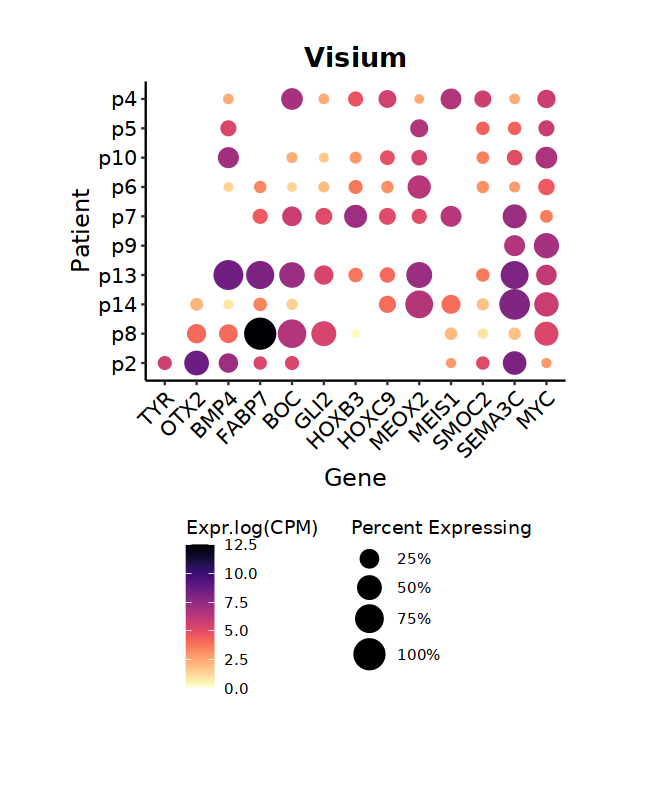

In [22]:
options(repr.plot.width = 5.5, repr.plot.height = 6.6, warn=-1,verbose = FALSE)
dp2 <-  ggplot(expression_df2, aes(x = Patient, y = Gene)) +
  geom_point(aes(size =  ifelse(PercentExpressing > 0, PercentExpressing, NA), color = Expression)) +
  theme_classic() +
  scale_colour_gradientn(colors = color_palette, name = leg_name) +
  scale_size_continuous(
      range = c(1, 8),
      limits = c(0, 100),
      breaks = c(25, 50, 75, 100),
      labels = c("25%", "50%", "75%", "100%"),
      name = "Percent Expressing") +
 ggtitle("Visium") + 
 theme(plot.title = element_text(hjust = 0.5, size = 16, face = "bold"),
      axis.title.x = element_text(size = 14, color="black"), 
      axis.title.y = element_text(size = 14, color="black"),  
      axis.text.x = element_text(size = 12, color="black", angle = 45,  vjust = 1, hjust = 1),   
      axis.text.y = element_text(size = 12, color="black"),
      legend.position = "bottom",
      legend.direction = "vertical",
      plot.margin = unit(c(10, 20, 20,15), "mm")) +
  guides(color = guide_colorbar(order = 1), 
       size = guide_legend(order = 2, ncol=1), ncol=1) +
  labs(x = "Patient", y = "Gene", color = "Expression", size = "Percent Expressing") +
  coord_flip()
dp2

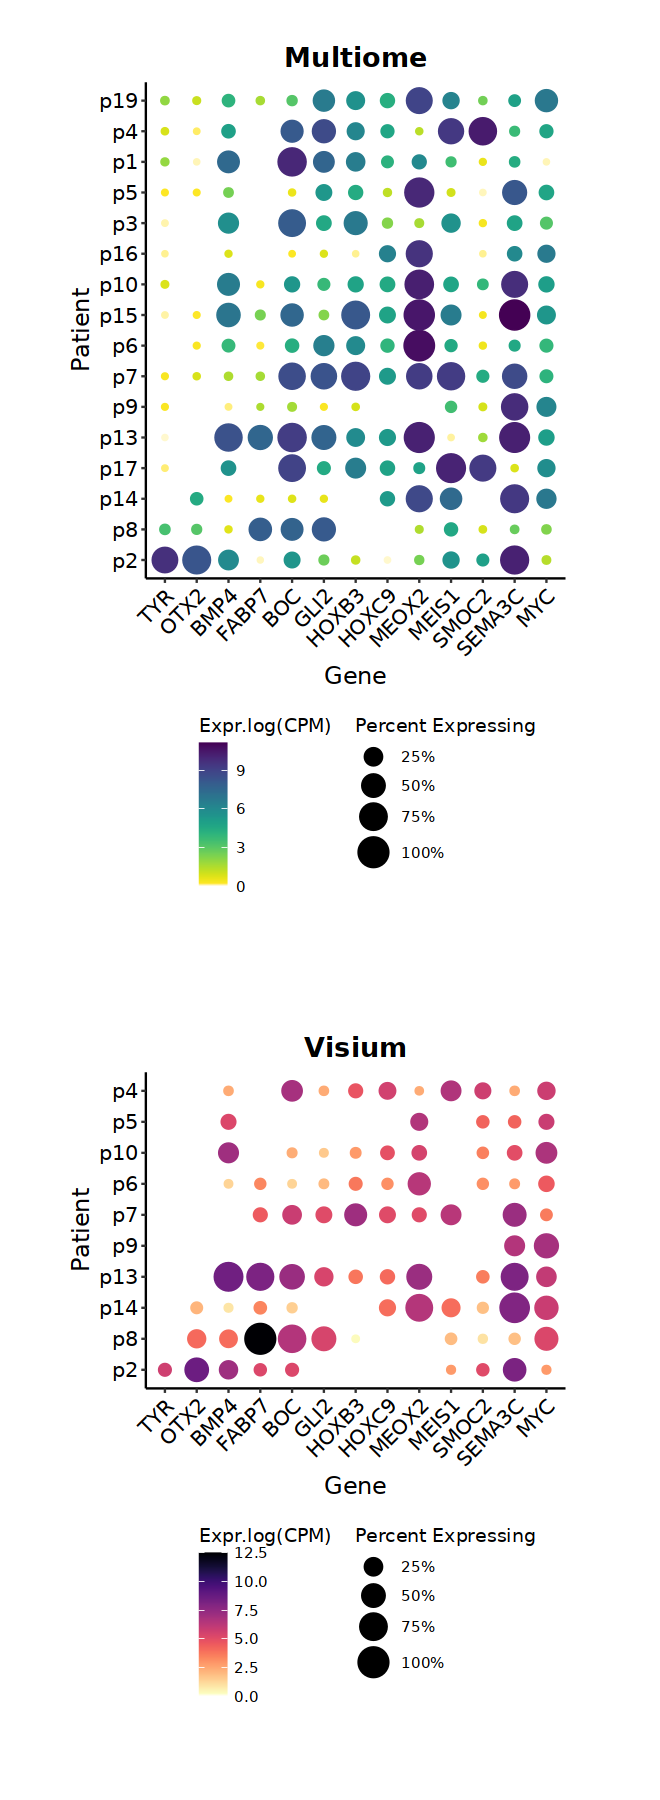

In [23]:
options(repr.plot.width = 5.5, repr.plot.height = 15, warn=-1,verbose = FALSE)
cp <- cowplot::plot_grid(dp1, dp2,
                   align = "v",
                   ncol = 1,
                   rel_heights = c(5.5, 4.5))
cp

In [24]:
ggsave(plot = cp, width = 5.5, height = 15, dpi = 300, 
       file = here::here(glue::glue("{int}/{plt_dir}/4.1.1-lite_markers_both.svg")))

In [25]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1c/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] grid      stats4    stats     graphics  grDevices utils     datasets 
[8] methods   base     

other attached packages:
 [1] glue_1.6.2                  here_1.0.1                 
 [3] ComplexHeatmap_2.10.0       ggsignif_0.6.4             
 [5] edgeR_3.36.0                limma_3.50.3               
 [7] scran_1.22.1                scater_1.22.0              
 [9] scuttle_